# 03- Modelagem: prevendo a popularidade de jogos da Steam

**Pergunta:** dá para prever a faixa de `peak_ccu` (pico de jogadores simultâneos) a partir das características da página do jogo?

**Alvo principal:** classificação em 4 faixas (`0`, `1-20`, `21-500`, `500+`), com **F1-macro** como métrica, porque 77,7% dos jogos estão na faixa 0 e só 1,0% na faixa 500+ (a acurácia seria enganosa).
**Complemento:** regressão em `log1p(peak_ccu)`.

Foram escolhidos três modelos de classificação para o projeto:

- **Regressão Logística:** modelo utilizado como referência para classificação, com ajuste de pesos para lidar com o desbalanceamento das classes.
- **MLP:** rede neural com duas camadas ocultas, contendo 64 e 32 neurônios.
- **Random Forest:** conjunto de árvores de decisão, utilizando 200 árvores.

Também foi utilizado um **Baseline**, que sempre prevê a classe mais frequente. Ele serve como referência para verificar se os modelos conseguem superar uma previsão simples.


**Roteiro**
1. Carga dos dados e split estratificado
2. Pré-processamento
3. Tratamento do desbalanceamento
4. Validação cruzada (5 folds) no treino
5. Avaliação final no teste
6. Importância das variáveis
7. Regressão complementar
8. Discussão

> Antes de rodar: o 01 e o 02 precisam ter gerado `../data/processed/features.parquet`.

In [177]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.float_format", "{:.3f}".format)
SEED = 42

## 3.1 - Importação dos dados e split

In [178]:
dados = pd.read_parquet("../data/processed/features.parquet")
if "AppID" in dados.columns:
    dados = dados.set_index("AppID")

ordem = ["0", "1-20", "21-500", "500+"]

# alvos e colunas de vazamentos nunca entram como preditoras
alvos = [c for c in ["peak_ccu", "log_ccu", "faixa_ccu"] if c in dados.columns]
vazamentos = ["positive", "negative", "recommendations", "estimated_owners", "n_tags"]

print("faixa_ccu nulos:", dados["faixa_ccu"].isna().sum())
y_cls = dados["faixa_ccu"].astype(str)
y_reg = dados["log_ccu"] if "log_ccu" in dados.columns else np.log1p(dados["peak_ccu"])

x = dados.drop(columns=alvos + [c for c in vazamentos if c in dados.columns])
x = x.drop(columns=[c for c in x.columns if c.startswith(("pct_pos", "num_reviews"))])
x = x.select_dtypes(exclude=["datetime", "datetimetz"])

# categóricas viram códigos (NaN fica NaN); bool vira int8 só aqui, para o sklearn
for c in x.select_dtypes(["category", "object", "string"]).columns:
    x[c] = x[c].astype("category").cat.codes.replace(-1, np.nan)
x = x.astype({c: "int8" for c in x.select_dtypes("bool").columns})
# tipos anuláveis do pandas (Int64, boolean) viram float, que o sklearn aceita com NaN
for c in x.columns:
    if pd.api.types.is_extension_array_dtype(x[c]):
        x[c] = x[c].astype("float64")

print("x:", x.shape)
print("Colunas não numéricas restantes:", list(x.select_dtypes(exclude="number").columns))
print(y_cls.value_counts(normalize=True).reindex(ordem).round(3))

faixa_ccu nulos: 0
x: (83646, 42)
Colunas não numéricas restantes: []
faixa_ccu
0        0.777
1-20     0.173
21-500   0.041
500+     0.010
Name: proportion, dtype: float64


In [179]:
x_tr, x_te, y_tr, y_te, yr_tr, yr_te = train_test_split(
    x, y_cls, y_reg, test_size=0.2, stratify=y_cls, random_state=SEED
)
print("treino:", x_tr.shape, "| teste:", x_te.shape)
print(y_te.value_counts().reindex(ordem))

treino: (66916, 42) | teste: (16730, 42)
faixa_ccu
0         12994
1-20       2888
21-500      687
500+        161
Name: count, dtype: int64


## 3.2 - Pré-processamento

- **Regressão logística e MLP** precisam de escala: variáveis de cauda longa (`preco`, `dlc`, `conquistas`, `n_idiomas`...) passam por `log1p` e depois por padronização.
- **Random Forest** não precisa de escala nem de log, só de imputação.
- Valores faltantes (por exemplo, a nota do Metacritic) são preenchidos com a mediana; a flag `tem_metacritic` já guarda a informação de que o dado não existia.
- Os pré-processadores ficam dentro do `Pipeline`, então são ajustados só no treino de cada fold (sem vazamento da validação).

In [180]:
cauda_longa = ["preco", "dlc", "conquistas", "n_idiomas", "n_categorias", "n_generos", "n_devs", "idade_minima"]
cols_log = [c for c in cauda_longa if c in X.columns]
cols_resto = [c for c in X.columns if c not in cols_log]


def prep_linear():
    return ColumnTransformer([
        ("log", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(np.log1p)),
            ("esc", StandardScaler()),
        ]), cols_log),
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("esc", StandardScaler()),
        ]), cols_resto),
    ])


def prep_arvore():
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), list(X.columns))])

## 3.3 - Balanceamento das classes no treino

- **Regressão logística e Random Forest:** `class_weight` (`balanced` e `balanced_subsample`).
- **MLP:** o `MLPClassifier` do scikit-learn não tem `class_weight`. Solução: reamostrar **só o treino** de cada fold, com `N_POR_CLASSE` linhas por classe (subamostra a classe 0, que é enorme, e repete linhas das classes raras). A validação e o teste ficam com a distribuição original.

Limitação: na faixa `500+` o treino tem poucas centenas de jogos, então a repetição de linhas aumenta o risco de a rede decorar esses exemplos.

In [181]:
np_classe = 11000


def rebalancear(X_, y_, n=np_classe, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = []
    for classe in np.unique(y_):
        pos = np.flatnonzero(y_.values == classe)
        idx.append(rng.choice(pos, size=n, replace=len(pos) < n))
    idx = np.concatenate(idx)
    rng.shuffle(idx)
    return X_.iloc[idx], y_.iloc[idx]

## 3.4 - Modelos e validação cruzada 

In [182]:
def logreg():
    return Pipeline([
        ("prep", prep_linear()),
        ("m", LogisticRegression(
            class_weight="balanced", 
            max_iter=1000,
            random_state=SEED)),
    
    ])


def mlp():
    return Pipeline([
        ("prep", prep_linear()),
        ("m", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=100, random_state=SEED)),
    ])


def random_forest():
    return Pipeline([
        ("prep", prep_arvore()),
        ("m", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2, 
            class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED)),
    ])


modelos = {
    "Baseline (classe majoritária)": (lambda: DummyClassifier(strategy="most_frequent"), False),
    "Regressão logística": (logreg, False),
    "MLP": (mlp, True),
    "Random Forest": (random_forest, False),
}

### Para avaliar os modelos, foram utilizadas diferentes métricas:

- **F1-score:** combina precisão e recall em uma única medida. Quanto maior o resultado, melhor o equilíbrio entre essas duas métricas.
- **F1-macro:** calcula o F1-score de cada classe e faz uma média simples entre elas. Dessa forma, todas as classes possuem o mesmo peso, independentemente da quantidade de jogos.
- **Acurácia balanceada:** calcula a média do recall de todas as classes, evitando que as classes mais numerosas dominem o resultado.

In [183]:
import os
import time
import warnings
from joblib import Parallel, delayed

n_par = min(5, os.cpu_count() or 1)
folds_em_paralelo = {"Regressão logística": n_par, "MLP": n_par}


def _um_fold(construir, X_, y_, tr, va, reb):
    warnings.filterwarnings("ignore", category=ConvergenceWarning)  # os processos novos não herdam o filtro
    Xf, yf = X_.iloc[tr], y_.iloc[tr]
    if reb:
        Xf, yf = rebalancear(Xf, yf)
    modelo = construir().fit(Xf, yf)
    return f1_score(y_.iloc[va], modelo.predict(X_.iloc[va]), average="macro")


def avaliar_cv(construir, X_, y_, com_rebalanceamento=False, n_splits=5, n_jobs=1):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    notas = Parallel(n_jobs=n_jobs)(
        delayed(_um_fold)(construir, X_, y_, tr, va, com_rebalanceamento)
        for tr, va in skf.split(X_, y_)
    )
    return np.array(notas)


linhas = []
for nome, (construir, reb) in modelos.items():
    print(f"{nome:32s}", end=" ", flush=True)
    t0 = time.time()
    notas = avaliar_cv(construir, X_tr, y_tr, reb, n_jobs=folds_em_paralelo.get(nome, 1))
    linhas.append({"modelo": nome, "F1-macro (média)": notas.mean(), "desvio": notas.std()})
    print(f"{notas.mean():.3f} ± {notas.std():.3f}  ({time.time() - t0:.0f}s)")

tabela_cv = pd.DataFrame(linhas).set_index("modelo")
tabela_cv

Baseline (classe majoritária)    0.219 ± 0.000  (1s)
Regressão logística              0.283 ± 0.003  (7s)
MLP                              0.282 ± 0.004  (37s)
Random Forest                    0.301 ± 0.004  (21s)


,F1-macro (média),desvio
modelo,,
Baseline (classe majoritária),0.219,0.000
Regressão logística,0.283,0.003
MLP,0.282,0.004
Random Forest,0.301,0.004


#### Validação cruzada (Cross-validation)

Foi utilizada a validação cruzada com 5 folds. Os folds são divisões do conjunto de treinamento em cinco partes.

Em cada repetição, quatro partes são utilizadas para treinar o modelo e uma para validação. Esse processo é repetido cinco vezes, alternando a parte utilizada para validação.

Ao final, são calculadas a média e o desvio dos resultados. A média representa o desempenho geral, enquanto o desvio indica quanto os resultados variaram entre as divisões.

## 3.5 - Avaliação final no teste

In [184]:
finais, previsoes, linhas = {}, {}, []
for nome, (construir, reb) in modelos.items():
    xf, yf = rebalancear(x_tr, y_tr) if reb else (x_tr, y_tr)
    modelo = construir().fit(xf, yf)
    pred = modelo.predict(x_te)
    finais[nome], previsoes[nome] = modelo, pred
    f1_classes = f1_score(y_te, pred, labels=ordem, average=None, zero_division=0)
    linhas.append({
        "modelo": nome,
        "F1-macro": f1_score(y_te, pred, average="macro", zero_division=0),
        "acurácia balanceada": balanced_accuracy_score(y_te, pred),
        **{f"F1 {c}": v for c, v in zip(ordem, f1_classes)},
    })

tabela_teste = pd.DataFrame(linhas).set_index("modelo")
tabela_teste

,F1-macro,acurácia balanceada,F1 0,F1 1-20,F1 21-500,F1 500+
modelo,,,,,,
Baseline (classe majoritária),0.219,0.250,0.874,0.000,0.000,0.000
Regressão logística,0.284,0.407,0.683,0.258,0.132,0.063
MLP,0.283,0.393,0.710,0.240,0.122,0.061
Random Forest,0.297,0.393,0.724,0.264,0.136,0.061



A tabela apresenta o desempenho dos modelos no conjunto de teste, considerando o F1-macro, a acurácia balanceada e o F1-score de cada classe.

O Random Forest obteve o melhor F1-macro, com 0,297, seguido pela regressão logística (0,284) e pelo MLP (0,283). Entretanto, a regressão logística apresentou a maior acurácia balanceada, com 0,407.

Observando as classes individualmente, o Random Forest teve o melhor resultado nas categorias `0`, `1-20` e `21-500`. Já na categoria `500+`, a regressão logística apresentou o melhor F1-score, embora o resultado também tenha sido baixo.

De modo geral, os resultados mostram que nenhum modelo teve desempenho elevado em todas as classes, principalmente nas faixas de maior popularidade.

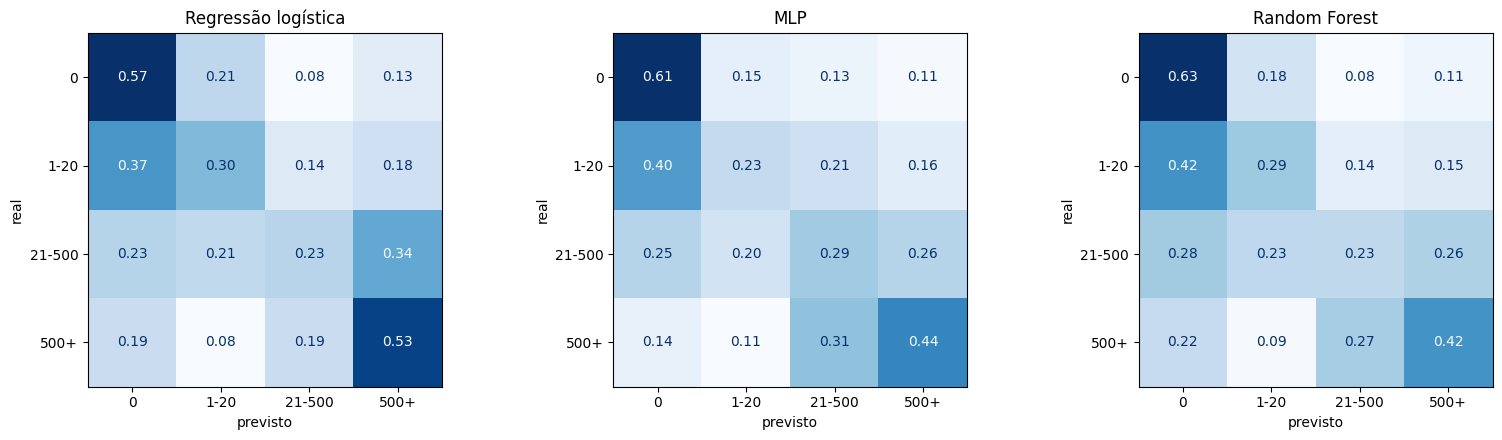

In [185]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, nome in zip(eixos, list(modelos)[1:]):
    ConfusionMatrixDisplay.from_predictions(
        y_te, previsoes[nome], labels=ordem, normalize="true",
        values_format=".2f", colorbar=False, cmap="Blues", ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("previsto")
    ax.set_ylabel("real")
plt.tight_layout()
plt.show()

Os três modelos apresentaram maior facilidade para identificar jogos da classe 0. O Random Forest obteve o melhor resultado nessa faixa, acertando 63% dos casos,
Nas classes intermediárias, principalmente `1-20` e `21-500`, houve maior dificuldade de classificação, com muitos jogos sendo confundidos com outras faixas
Na classe `500+`, a regressão logística apresentou o melhor resultado, identificando corretamente 53% dos casos, seguida pelo MLP (44%) e pelo Random Forest (42%)
De forma geral, as matrizes mostram que os modelos conseguem identificar parte dos jogos mais populares, mas ainda apresentam confusão entre as faixas, especialmente nas classes intermediárias

## 3.6 - Importância das variáveis (Random Forest)

Importância por permutação no teste: quanto o F1-macro cai quando os valores de uma variável são embaralhados. Variáveis correlacionadas (por exemplo, `n_idiomas` e `tem_dublagem`) dividem a importância entre si.

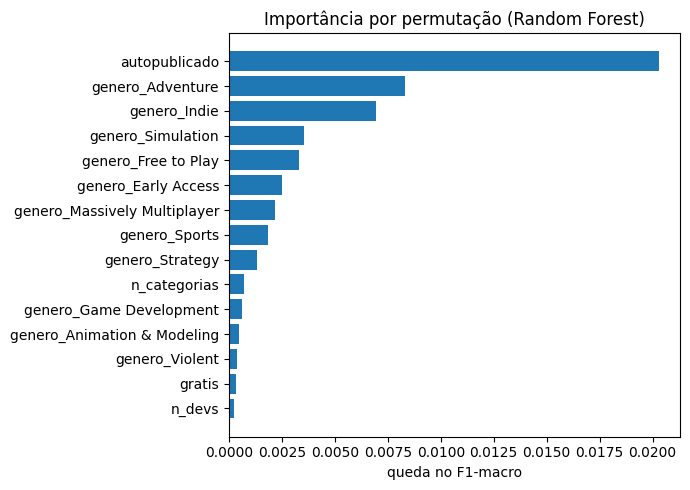

In [186]:
amostra = x_te.sample(min(5000, len(x_te)), random_state=SEED)
y_amostra = y_te.loc[amostra.index]

perm = permutation_importance(
    finais["Random Forest"], amostra, y_amostra,
    scoring="f1_macro", n_repeats=3, random_state=SEED,
)
imp = pd.Series(perm.importances_mean, index=x.columns).sort_values(ascending=False)

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values)
plt.xlabel("queda no F1-macro")
plt.title("Importância por permutação (Random Forest)")
plt.tight_layout()
plt.show()

O gráfico apresenta a importância das variáveis no Random Forest, medida por permutação. Quanto maior a queda no F1-macro após embaralhar uma variável, maior sua contribuição para o desempenho do modelo.

A variável `autopublicado` apresentou a maior importância, destacando-se bastante em relação às demais. Em seguida, aparecem os gêneros `Adventure` e `Indie`, além de `Simulation` e `Free to Play`.

Já variáveis como `gratis`, `n_devs` e algumas categorias de gênero apresentaram pouca influência no resultado.

Esses resultados indicam que o modelo utiliza principalmente a informação de publicação e determinados gêneros para identificar as faixas de popularidade dos jogos. Entretanto, essa importância representa a contribuição para as previsões do modelo e não significa necessariamente uma relação de causa e efeito.

In [187]:
print(tabela_cv.to_string())
print(tabela_teste.to_string())

                               F1-macro (média)  desvio
modelo                                                 
Baseline (classe majoritária)             0.219   0.000
Regressão logística                       0.283   0.003
MLP                                       0.282   0.004
Random Forest                             0.301   0.004
                               F1-macro  acurácia balanceada  F1 0  F1 1-20  F1 21-500  F1 500+
modelo                                                                                         
Baseline (classe majoritária)     0.219                0.250 0.874    0.000      0.000    0.000
Regressão logística               0.284                0.407 0.683    0.258      0.132    0.063
MLP                               0.283                0.393 0.710    0.240      0.122    0.061
Random Forest                     0.297                0.393 0.724    0.264      0.136    0.061


### Comparação dos resultados
Na validação cruzada, o Random Forest apresentou o melhor F1-macro médio, com 0,301, seguido pela regressão logística (0,283) e pelo MLP (0,282). Os desvios foram baixos, indicando pouca variação entre os folds.
No conjunto de teste, o Random Forest também obteve o melhor resultado, com F1-macro de 0,297. A regressão logística alcançou 0,284 e o MLP, 0,283.
Em relação às classes, todos os modelos tiveram maior facilidade para identificar jogos com pico de jogadores igual a zero. Já as classes mais populares apresentaram resultados inferiores, principalmente a categoria `500+`.
Apesar de superar o baseline, os resultados mostram que os modelos ainda possuem dificuldades para classificar corretamente os jogos de maior popularidade.

## 3.7 - Regressão complementar: `log1p(peak_ccu)`

Mesmo split do treino e do teste. Como 77,7% dos jogos têm `peak_ccu = 0`, o alvo tem uma montanha em zero e o R² tende a ser baixo. Para comparar com a classificação, as previsões também são convertidas nas 4 faixas: os cortes ficam nos quantis das previsões, de modo que cada faixa prevista tenha a proporção que ela tem no treino (um corte fixo em log1p(20) quase nunca seria atingido, porque a regressão tende à média).

In [188]:
def ridge():
    return Pipeline([("prep", prep_linear()), ("m", Ridge(alpha=1.0))])


def mlp_reg():
    return Pipeline([
        ("prep", prep_linear()),
        ("m", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                           n_iter_no_change=10, max_iter=200, random_state=SEED)),
    ])


def rf_reg():
    return Pipeline([
        ("prep", prep_arvore()),
        ("m", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
    ])


modelos_reg = {
    "Baseline (média)": lambda: DummyRegressor(strategy="mean"),
    "Ridge": ridge,
    "MLP": mlp_reg,
    "Random Forest": rf_reg,
}

# proporção acumulada de cada faixa no treino: 0 | 1-20 | 21-500 | 500+
proporcao_acumulada = y_tr.value_counts(normalize=True).reindex(ordem).fillna(0).cumsum().values[:-1]


def para_faixa(pred_log):
    cortes = np.quantile(pred_log, proporcao_acumulada)
    return np.array(ordem)[np.digitize(pred_log, cortes, right=True)]


linhas = []
for nome, construir in modelos_reg.items():
    modelo = construir().fit(x_tr, yr_tr)
    pred = modelo.predict(x_te)
    linhas.append({
        "modelo": nome,
        "RMSE": np.sqrt(mean_squared_error(yr_te, pred)),
        "MAE": mean_absolute_error(yr_te, pred),
        "R²": r2_score(yr_te, pred),
        "F1-macro (em faixas)": f1_score(y_te, para_faixa(pred), average="macro", zero_division=0),
    })

tabela_reg = pd.DataFrame(linhas).set_index("modelo")
tabela_reg

,RMSE,MAE,R²,F1-macro (em faixas)
modelo,,,,
Baseline (média),1.225,0.734,-0.000,0.219
Ridge,1.172,0.674,0.084,0.319
MLP,1.164,0.684,0.096,0.324
Random Forest,1.150,0.653,0.118,0.342


Os três modelos de regressão superaram o baseline (que sempre prevê a média): o RMSE caiu de 1,225 para 1,150 no Random Forest, e o MAE de 0,734 para 0,653. Mesmo assim, o R² ficou baixo (0,084 na Ridge, 0,096 no MLP e 0,118 no Random Forest), ou seja, as variáveis da página explicam só uma pequena parte da variação do log1p(peak_ccu). Isso é esperado, já que 77,7% dos jogos têm pico igual a zero e o alvo se concentra nesse valor. A ordem dos modelos se repete em relação à classificação: o Random Forest é o melhor, e a Ridge e o MLP ficam próximos.

Convertidas nas 4 faixas, as previsões da regressão tiveram F1-macro de 0,319 (Ridge), 0,324 (MLP) e 0,342 (Random Forest), acima dos 0,297 do Random Forest classificador. Esse resultado não deve ser lido como “a regressão é melhor”: a conversão usa cortes por quantil, que forçam as faixas previstas a terem as proporções do treino, enquanto os classificadores com class_weight tendem a prever as faixas raras com mais frequência, o que reduz a precisão. São regras de decisão diferentes, então a comparação direta é apenas indicativa. A regressão serve aqui como complemento, reforçando que há algum sinal nas variáveis, mas que ele é modesto.

## 3.8 - Experimento com `n_tags`

Foi realizado um teste para verificar se adicionar a quantidade de tags dos jogos (`n_tags`) melhoraria o desempenho do Random Forest.

Foram comparados dois cenários: um sem essa variável e outro com ela. Os valores ausentes foram tratados como `NaN` e substituídos pela mediana durante o processamento.

Os resultados mostraram uma diferença de aproximadamente **-0,0008 no F1-macro** ao adicionar `n_tags`.

Portanto, a inclusão dessa variável praticamente não alterou o desempenho do modelo e não trouxe uma melhoria significativa.

In [ ]:


dados_tags = pd.read_parquet("../data/processed/y.parquet")
if "AppID" in dados_tags.columns:
    dados_tags = dados_tags.set_index("AppID")

n_tags = pd.to_numeric(
    dados_tags["n_tags"], errors="coerce"
).reindex(x.index)

assert n_tags.notna().any(), "Não foi possível alinhar n_tags com x."

# 2. Criar os dois cenários
x_tr_com_tags = x_tr.assign(
    n_tags=n_tags.reindex(x_tr.index)
)

x_te_com_tags = x_te.assign(
    n_tags=n_tags.reindex(x_te.index)
)

# 3. Random Forest com colunas configuráveis
def rf_experimento(colunas):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), list(colunas))
        ])),
        ("m", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=SEED
        ))
    ])

# 4. Executar comparação
cenarios = [
    ("Sem n_tags", x_tr, x_te),
    ("Com n_tags", x_tr_com_tags, x_te_com_tags)
]

resultados = []

for nome, xtreino, xteste in cenarios:

    construir = lambda: rf_experimento(xtreino.columns)

    # Validação cruzada
    notas = avaliar_cv(
        construir,
        xtreino,
        y_tr,
        com_rebalanceamento=False,
        n_splits=5
    )

    # Teste final
    modelo = construir()
    modelo.fit(xtreino, y_tr)
    pred = modelo.predict(xteste)

    resultados.append({
        "Cenário": nome,
        "F1-macro CV": notas.mean(),
        "Desvio CV": notas.std(),
        "F1-macro teste": f1_score(
            y_te, pred, average="macro"
        ),
        "Acurácia": (pred == y_te).mean()
    })

tabela_tags = pd.DataFrame(resultados).set_index("Cenário")

display(tabela_tags)

# 5. Diferença entre os cenários
print("\nDiferença no F1-macro do teste:")
print(
    tabela_tags.loc["Com n_tags", "F1-macro teste"]
    - tabela_tags.loc["Sem n_tags", "F1-macro teste"]
)
